# Clustering Track — Gene Expression Cancer RNA-Seq (UCI)
**Goal:** group tumour samples by gene-expression profile with **no labels used during fitting**.
The known cancer types are only used *afterwards* to validate the clusters (rubric §3.3).

Algorithms: **K-Means** (elbow curve) and **Agglomerative Hierarchical** (dendrogram, linkage comparison).
Metrics: Silhouette, Davies-Bouldin, Calinski-Harabasz. Visuals: PCA 2-D (mandatory) and t-SNE.



In [5]:
# ── Setup ─────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.manifold import TSNE
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.dpi"] = 100


Load and Audit

In [9]:
import pandas as pd
from pathlib import Path

# Locate the Seeds dataset
DATA_DIR = Path("../data")

data_path = DATA_DIR / "seeds_dataset.txt"

# Column names for the Seeds dataset
columns = [
    "Area",
    "Perimeter",
    "Compactness",
    "Kernel_Length",
    "Kernel_Width",
    "Asymmetry_Coefficient",
    "Kernel_Groove_Length",
    "Class"
]

# Load the tab-separated file
df = pd.read_csv(
    data_path,
    sep=r"\s+",
    header=None,
    names=columns
)

# Separate features and labels
expr = df.drop(columns=["Class"])
labels = df["Class"]

# Display dataset information
print("Dataset shape (samples x features):", expr.shape)
print("Labels shape:", labels.shape)
print("\nFirst five rows:")
print(df.head())

print("\nMissing values:", int(df.isnull().sum().sum()))
print("Duplicate samples:", int(df.duplicated().sum()))
print("\nClass counts:")
print(labels.value_counts().sort_index())

Dataset shape (samples x features): (210, 7)
Labels shape: (210,)

First five rows:
    Area  Perimeter  Compactness  Kernel_Length  Kernel_Width  \
0  15.26      14.84       0.8710          5.763         3.312   
1  14.88      14.57       0.8811          5.554         3.333   
2  14.29      14.09       0.9050          5.291         3.337   
3  13.84      13.94       0.8955          5.324         3.379   
4  16.14      14.99       0.9034          5.658         3.562   

   Asymmetry_Coefficient  Kernel_Groove_Length  Class  
0                  2.221                 5.220      1  
1                  1.018                 4.956      1  
2                  2.699                 4.825      1  
3                  2.259                 4.805      1  
4                  1.355                 5.175      1  

Missing values: 0
Duplicate samples: 0

Class counts:
Class
1    70
2    70
3    70
Name: count, dtype: int64


**Observation:** *(samples vs genes — far more features than samples; note missing values, class balance, and why this "p >> n" shape makes scaling + PCA essential.)*

## EDA — gene-level variance

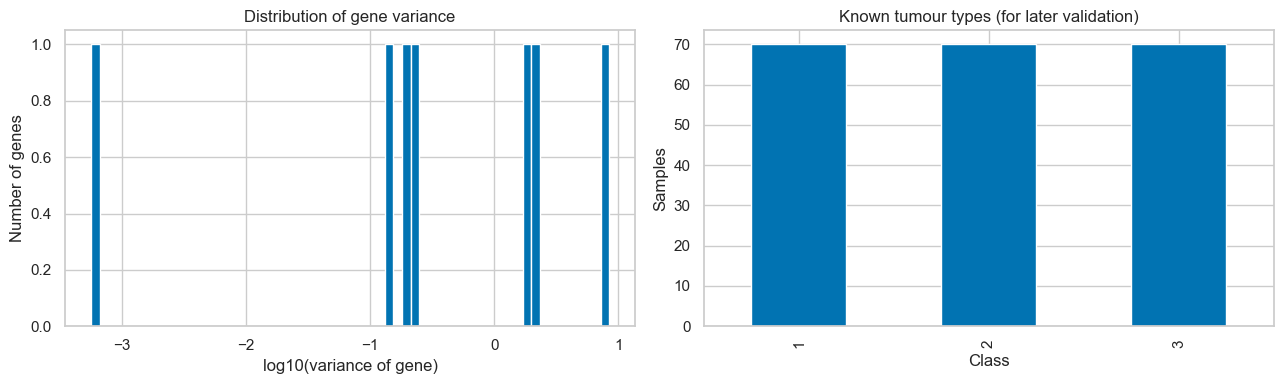

Zero-variance genes: 0


In [10]:
gene_var = expr.var()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(np.log10(gene_var[gene_var > 0]), bins=60)
axes[0].set_xlabel("log10(variance of gene)"); axes[0].set_ylabel("Number of genes")
axes[0].set_title("Distribution of gene variance")

if labels is not None:
    labels.value_counts().plot(kind="bar", ax=axes[1])
    axes[1].set_title("Known tumour types (for later validation)")
    axes[1].set_xlabel("Class"); axes[1].set_ylabel("Samples")
plt.tight_layout(); plt.savefig("../models/clu_eda.png", bbox_inches="tight"); plt.show()

print("Zero-variance genes:", int((gene_var == 0).sum()))


**Observation:** *(most genes have low variance — only a subset varies enough to separate tumour types, which motivates variance filtering.)*

## Preprocessing — variance filter, scaling, PCA(50)


Genes kept: 7


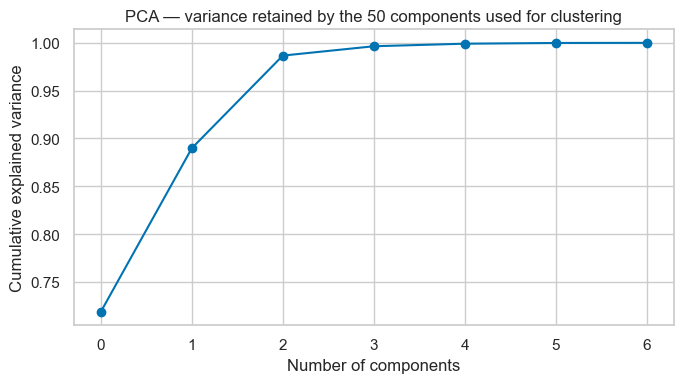

Variance retained by 7 components: 1.000


In [11]:
# Drop constant genes, keep the most variable ones, then standardise.
# (Clustering has no train/test split, so scaling on the full matrix is not leakage.)
X = expr.loc[:, gene_var > 0]
TOP_GENES = min(2000, X.shape[1])
top_genes = X.var().sort_values(ascending=False).head(TOP_GENES).index
X = X[top_genes]
print("Genes kept:", X.shape[1])

scaler_clu = StandardScaler().fit(X)          # kept (not thrown away) so the GUI can reuse it
X_scaled = scaler_clu.transform(X)

# PCA to 50 components: removes noise, makes distance-based clustering meaningful in high dimensions
pca50 = PCA(n_components=min(50, X_scaled.shape[1]), random_state=RANDOM_STATE)
X_pca = pca50.fit_transform(X_scaled)

plt.figure(figsize=(7, 4))
plt.plot(np.cumsum(pca50.explained_variance_ratio_), marker="o")
plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance")
plt.title("PCA — variance retained by the 50 components used for clustering")
plt.tight_layout(); plt.savefig("../models/clu_pca_variance.png", bbox_inches="tight"); plt.show()
print(f"Variance retained by {pca50.n_components_} components: {pca50.explained_variance_ratio_.sum():.3f}")


## K-Means — Elbow curve (and silhouette) to choose k

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

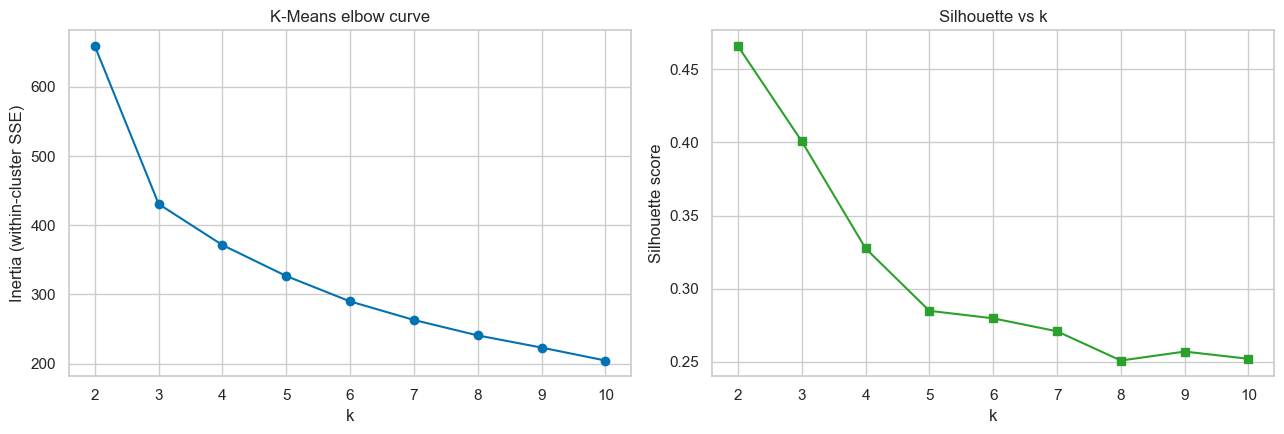

K chosen: 2


In [12]:
k_range = range(2, 11)
inertias, sils = [], []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_pca)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_pca, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(list(k_range), inertias, marker="o")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia (within-cluster SSE)"); axes[0].set_title("K-Means elbow curve")
axes[1].plot(list(k_range), sils, marker="s", color="tab:green")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette score"); axes[1].set_title("Silhouette vs k")
plt.tight_layout(); plt.savefig("../models/clu_elbow.png", bbox_inches="tight"); plt.show()

# Default: the k with the best silhouette. Override K_CHOSEN if the elbow tells a different story.
K_CHOSEN = list(k_range)[int(np.argmax(sils))]
print("K chosen:", K_CHOSEN)


**Observation:** *(where does the elbow bend? does the silhouette peak agree? justify K_CHOSEN in your own words.)*

In [13]:
kmeans = KMeans(n_clusters=K_CHOSEN, n_init=10, random_state=RANDOM_STATE).fit(X_pca)
km_labels = kmeans.labels_
print("K-Means cluster sizes:", np.bincount(km_labels))


K-Means cluster sizes: [ 77 133]


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


## Agglomerative Hierarchical — dendrogram + linkage comparison

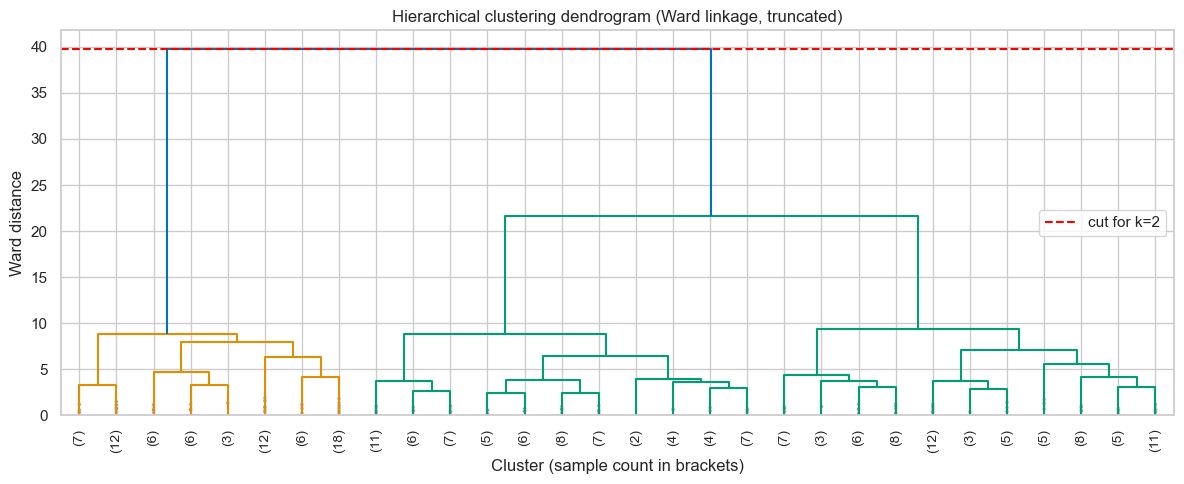

In [14]:
Z = linkage(X_pca, method="ward")
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, show_contracted=True)
plt.axhline(y=Z[-(K_CHOSEN - 1), 2], color="red", linestyle="--", label=f"cut for k={K_CHOSEN}")
plt.xlabel("Cluster (sample count in brackets)"); plt.ylabel("Ward distance")
plt.title("Hierarchical clustering dendrogram (Ward linkage, truncated)")
plt.legend(); plt.tight_layout(); plt.savefig("../models/clu_dendrogram.png", bbox_inches="tight"); plt.show()


In [15]:
# Compare linkage strategies at the same k
link_rows, agg_labels_by_link = [], {}
for link in ["ward", "complete", "average", "single"]:
    lab = AgglomerativeClustering(n_clusters=K_CHOSEN, linkage=link).fit_predict(X_pca)
    agg_labels_by_link[link] = lab
    link_rows.append({"Linkage": link,
                      "Silhouette": silhouette_score(X_pca, lab),
                      "Davies-Bouldin": davies_bouldin_score(X_pca, lab),
                      "Calinski-Harabasz": calinski_harabasz_score(X_pca, lab),
                      "Cluster sizes": np.bincount(lab).tolist()})
link_df = pd.DataFrame(link_rows).set_index("Linkage")
display(link_df)

# Silhouette alone can reward a degenerate result (one giant cluster + a few outliers, typical of
# average/single linkage). So only consider linkages whose smallest cluster holds >= 2% of samples.
min_frac = {l: min(np.bincount(agg_labels_by_link[l])) / len(X_pca) for l in agg_labels_by_link}
valid = [l for l in link_df.index if min_frac[l] >= 0.02]
BEST_LINK = link_df.loc[valid, "Silhouette"].idxmax() if valid else "ward"
print("Linkages with no degenerate (<2%) cluster:", valid)
agg_labels = agg_labels_by_link[BEST_LINK]
print("Linkage used for the final Agglomerative model:", BEST_LINK)


,Silhouette,Davies-Bouldin,Calinski-Harabasz,Cluster sizes
Linkage,,,,
ward,0.461297,0.782902,242.712003,"[140, 70]"
complete,0.451995,0.793176,230.310203,"[142, 68]"
average,0.441339,0.830841,227.656715,"[135, 75]"
single,0.056230,0.765582,1.479647,"[209, 1]"


Linkages with no degenerate (<2%) cluster: ['ward', 'complete', 'average']
Linkage used for the final Agglomerative model: ward


**Observation:** *(which linkage works best and why? single linkage usually chains points into one giant cluster — check the cluster sizes column.)*

## Evaluation metrics — all algorithms

In [16]:
def internal_metrics(name, labels_):
    return {"Algorithm": name,
            "Silhouette (higher better)": silhouette_score(X_pca, labels_),
            "Davies-Bouldin (lower better)": davies_bouldin_score(X_pca, labels_),
            "Calinski-Harabasz (higher better)": calinski_harabasz_score(X_pca, labels_)}

metrics_df = pd.DataFrame([internal_metrics("K-Means", km_labels),
                           internal_metrics(f"Agglomerative ({BEST_LINK})", agg_labels)]).set_index("Algorithm")
metrics_df.to_csv("../models/clustering_metrics.csv")
metrics_df.style.format("{:.4f}")


,Silhouette (higher better),Davies-Bouldin (lower better),Calinski-Harabasz (higher better)
Algorithm,,,
K-Means,0.4658,0.7969,255.8548
Agglomerative (ward),0.4613,0.7829,242.7120


**Observation:** *(which algorithm wins on each metric? do the three metrics agree? remember each one rewards a different notion of a "good" cluster.)*

## Cluster visualisation — PCA 2-D (mandatory) and t-SNE

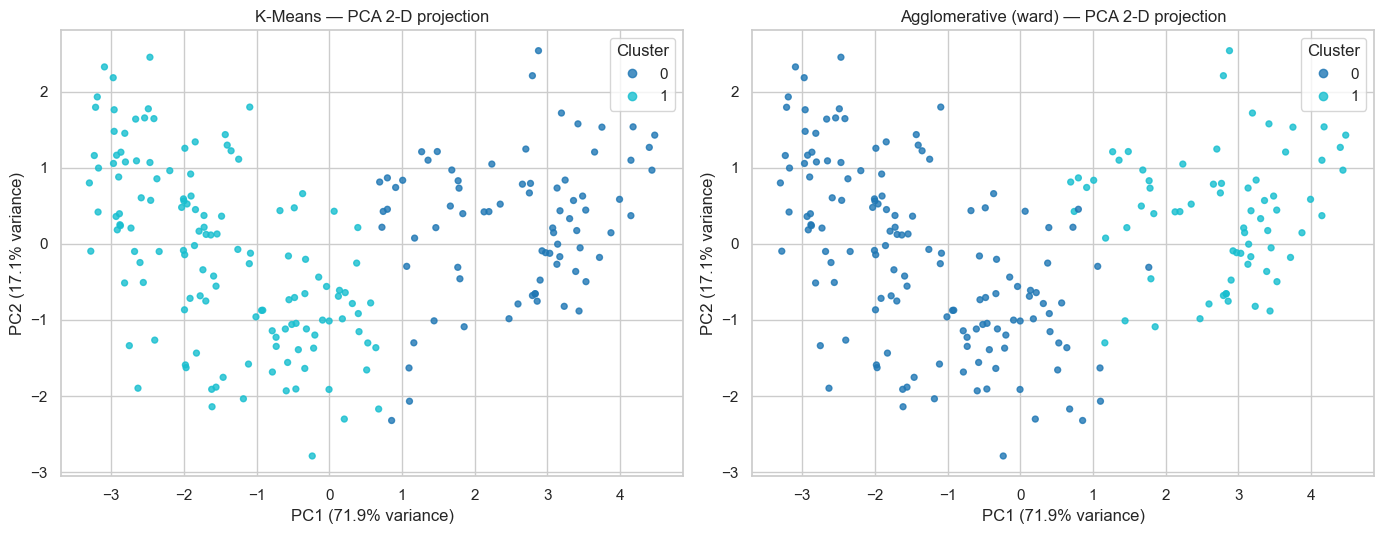

In [17]:
pca2 = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca2.fit_transform(X_scaled)
ev = pca2.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, lab, title in [(axes[0], km_labels, "K-Means"), (axes[1], agg_labels, f"Agglomerative ({BEST_LINK})")]:
    sc = ax.scatter(X_2d[:, 0], X_2d[:, 1], c=lab, cmap="tab10", s=18, alpha=0.8)
    ax.set_xlabel(f"PC1 ({ev[0]:.1%} variance)"); ax.set_ylabel(f"PC2 ({ev[1]:.1%} variance)")
    ax.set_title(f"{title} — PCA 2-D projection")
    ax.legend(*sc.legend_elements(), title="Cluster", loc="best")
plt.tight_layout(); plt.savefig("../models/clu_pca_2d.png", bbox_inches="tight"); plt.show()


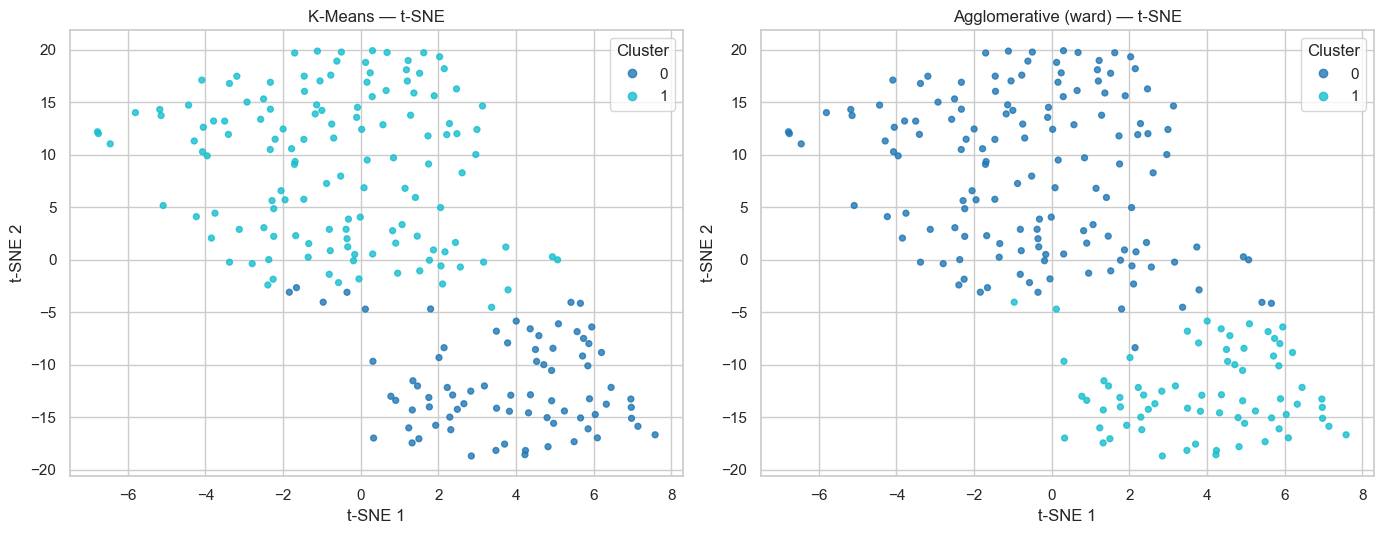

In [18]:
# t-SNE (slower; run on the 50 PCA components, not the raw genes)
perp = min(30, max(5, (len(X_pca) - 1) // 3))
X_tsne = TSNE(n_components=2, perplexity=perp, init="pca", random_state=RANDOM_STATE).fit_transform(X_pca)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, lab, title in [(axes[0], km_labels, "K-Means"), (axes[1], agg_labels, f"Agglomerative ({BEST_LINK})")]:
    sc = ax.scatter(X_tsne[:, 0], X_tsne[:, 1], c=lab, cmap="tab10", s=18, alpha=0.8)
    ax.set_xlabel("t-SNE 1"); ax.set_ylabel("t-SNE 2"); ax.set_title(f"{title} — t-SNE")
    ax.legend(*sc.legend_elements(), title="Cluster", loc="best")
plt.tight_layout(); plt.savefig("../models/clu_tsne.png", bbox_inches="tight"); plt.show()


**Observation:** *(are clusters compact and separated in PCA? does t-SNE separate groups that PCA overlaps? note that t-SNE distances between clusters are not meaningful — only the grouping is.)*

## Post-hoc validation against the known cancer types
Labels were **not** used above. Here they only measure how well the unsupervised clusters recover biology.

,Adjusted Rand Index,Normalized Mutual Info
Algorithm,,
K-Means,0.4805,0.5536
Agglomerative (ward),0.4762,0.5654


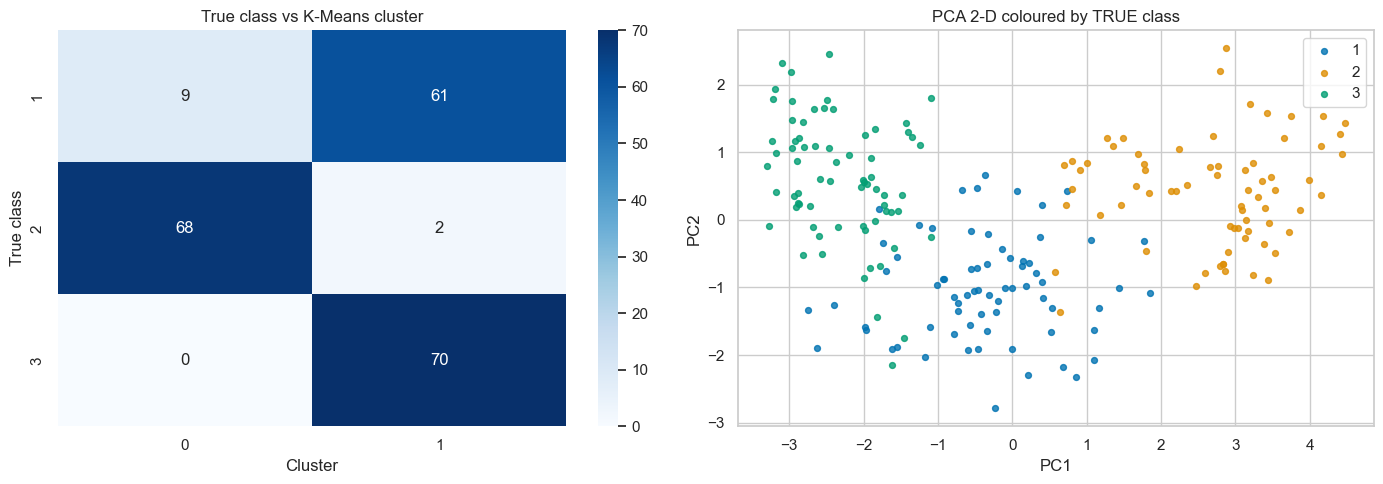

In [19]:
if labels is not None:
    val_rows = []
    for name, lab in [("K-Means", km_labels), (f"Agglomerative ({BEST_LINK})", agg_labels)]:
        val_rows.append({"Algorithm": name,
                         "Adjusted Rand Index": adjusted_rand_score(labels, lab),
                         "Normalized Mutual Info": normalized_mutual_info_score(labels, lab)})
    val_df = pd.DataFrame(val_rows).set_index("Algorithm")
    val_df.to_csv("../models/clustering_validation.csv")
    display(val_df.style.format("{:.4f}"))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.heatmap(pd.crosstab(labels, km_labels), annot=True, fmt="d", cmap="Blues", ax=axes[0])
    axes[0].set_title("True class vs K-Means cluster"); axes[0].set_xlabel("Cluster"); axes[0].set_ylabel("True class")
    for cls in sorted(labels.unique()):
        m = (labels == cls).values
        axes[1].scatter(X_2d[m, 0], X_2d[m, 1], s=18, alpha=0.8, label=cls)
    axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2"); axes[1].set_title("PCA 2-D coloured by TRUE class")
    axes[1].legend()
    plt.tight_layout(); plt.savefig("../models/clu_validation.png", bbox_inches="tight"); plt.show()
else:
    print("No labels.csv found — skipping validation.")


**Observation:** *(ARI/NMI close to 1 = clusters match tumour types. Which classes get merged or split, and what might explain that biologically?)*

## Save the models for the GUI
The notebook previously saved **no model at all** (only CSVs and PNGs). Each saved model is a full pipeline: raw top-gene row → scaler → PCA(50) → clusterer, so the GUI can feed it a raw expression row.
`AgglomerativeClustering` has no `predict()`, so it is saved as a nearest-centroid assigner trained on its own cluster labels.

In [20]:
# ══════════════════════════════════════════════════════════════════════
# SAVE MODELS FOR THE GUI  (replaces the old single-pickle save)
# Why: the old code put EVERY model in one dict inside one .pkl. If even one model (e.g. Gradient
# Boosting) can't be unpickled under another scikit-learn version, the whole file fails to load.
# Now: one .joblib per model + manifest.json (records the sklearn version) + a reload test right here.
# ══════════════════════════════════════════════════════════════════════
import joblib, json, re, platform, sklearn
from pathlib import Path

def save_track(track, models, features, scores_df, check_X, scaler=None, extras=None, models_root="../models"):
    out = Path(models_root) / track
    out.mkdir(parents=True, exist_ok=True)
    for old in out.glob("*.joblib"):          # remove stale files from earlier runs
        old.unlink()

    manifest = {"track": track, "sklearn": sklearn.__version__,
                "python": platform.python_version(), "models": {}, "extras": {}}
    for name, model in models.items():
        fn = re.sub(r"[^A-Za-z0-9]+", "_", name).strip("_") + ".joblib"
        joblib.dump(model, out / fn)
        manifest["models"][name] = fn
    if scaler is not None:
        joblib.dump(scaler, out / "scaler.joblib"); manifest["scaler"] = "scaler.joblib"
    for key, obj in (extras or {}).items():
        joblib.dump(obj, out / f"{key}.joblib"); manifest["extras"][key] = f"{key}.joblib"
    (out / "features.json").write_text(json.dumps(list(features)))
    scores_df.to_csv(out / "scores.csv", index=False)
    (out / "manifest.json").write_text(json.dumps(manifest, indent=2))

    # reload every file from disk and predict -> any problem shows up HERE, not later in the GUI
    failed = []
    for name, fn in manifest["models"].items():
        try:
            joblib.load(out / fn).predict(check_X)
        except Exception as e:
            failed.append(f"{name}: {type(e).__name__}: {e}")
    print(f"[{track}] saved {len(models)} models to {out.resolve()}")
    print(f"[{track}] reload + predict check: {len(models) - len(failed)}/{len(models)} OK")
    for f in failed:
        print("   FAILED ->", f)
    print(f"[{track}] put this in requirements.txt:  scikit-learn=={sklearn.__version__}   (Python {platform.python_version()})")

# ── Clustering: build pipelines + save ───────────────────────────────────
from sklearn.pipeline import Pipeline
from sklearn.neighbors import NearestCentroid

agg_assign = NearestCentroid().fit(X_pca, agg_labels)
clu_models = {
    f"K-Means (k={K_CHOSEN})": Pipeline([("scaler", scaler_clu), ("pca", pca50), ("model", kmeans)]),
    f"Agglomerative ({BEST_LINK}) - nearest-centroid assignment":
        Pipeline([("scaler", scaler_clu), ("pca", pca50), ("model", agg_assign)]),
}

scores_df = metrics_df.reset_index()
if labels is not None:
    scores_df = scores_df.merge(val_df.reset_index(), on="Algorithm")

save_track("clustering", clu_models, X.columns, scores_df, check_X=X.head(3))

# a few real samples so the GUI has something to try (raw top-gene values + the known class)
demo = X.sample(min(25, len(X)), random_state=RANDOM_STATE).copy()
if labels is not None:
    demo["true_class"] = labels.reindex(demo.index).values
demo.to_csv("../models/clustering/demo_samples.csv")
scores_df

[clustering] saved 2 models to D:\sem5\ml\proj\review 2\ML-Capstone\models\clustering
[clustering] reload + predict check: 2/2 OK
[clustering] put this in requirements.txt:  scikit-learn==1.7.2   (Python 3.13.9)


,Algorithm,Silhouette (higher better),Davies-Bouldin (lower better),Calinski-Harabasz (higher better),Adjusted Rand Index,Normalized Mutual Info
0,K-Means,0.465772,0.796879,255.854827,0.480528,0.553630
1,Agglomerative (ward),0.461297,0.782902,242.712003,0.476203,0.565368
